# DeepTuneIO Analyzer — Contention Analysis (v6)

Visualización de coincidencias DXT con títulos descriptivos y paletas seleccionables. Las coincidencias no demuestran por sí mismas degradación.


In [7]:
from pathlib import Path
import pandas as pd
import sys
from IPython.display import display, Image

# Localiza el módulo aunque Jupyter se abra desde la raíz del proyecto.
CANDIDATES = [
    Path.cwd(),
    Path.cwd() / "10_Visualization" / "Contention_Analysis",
    Path.cwd() / "Contention_Analysis",
]
ROOT = next((p.resolve() for p in CANDIDATES if (p / "Module" / "contention_pipeline.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        "No encuentro Module/contention_pipeline.py. Abre el notebook desde "
        "10_Visualization/Contention_Analysis o desde la raíz DeepTuneIO."
    )
ACCESS_PATTERN_MODULE = ROOT.parent / "Access_Pattern" / "Module"
if not (ACCESS_PATTERN_MODULE / "Access_Pattern_Visualization" / "processor.py").is_file():
    raise FileNotFoundError(
        f"Falta Access_Pattern: {ACCESS_PATTERN_MODULE}. "
        "Instala ambas carpetas al mismo nivel dentro de 10_Visualization."
    )
sys.path.insert(0, str(ACCESS_PATTERN_MODULE))
sys.path.insert(0, str(ROOT / "Module"))
from contention_pipeline import run_contention
print("Contention_Analysis:", ROOT)
print("Detector Access_Pattern:", ACCESS_PATTERN_MODULE)


Contention_Analysis: F:\NoteBooks\CORA_DR_UAB\Tesis\Scripts\DeepTuneIO\10_Visualization\Contention_Analysis
Detector Access_Pattern: F:\NoteBooks\CORA_DR_UAB\Tesis\Scripts\DeepTuneIO\10_Visualization\Access_Pattern\Module


## 4. Descubrir CSV de rendimiento y resultados DXT

Comprueba la tabla antes de ejecutar. Se pueden añadir rutas explícitas cuando los CSV estén almacenados fuera de la campaña.

In [8]:
# Patrones de búsqueda de archivos generados por módulos anteriores
PERF_GLOBS = ["results/**/*Perf*.csv", "results/**/*perf*.csv", "processed/**/*Perf*.csv"]
perf_files = sorted({p for pattern in PERF_GLOBS for p in CAMPAIGN_ROOT.glob(pattern) if p.is_file()})
# Si los CSV están en otro directorio, añade rutas completas aquí.
EXTRA_PERF_FILES = []
perf_files = sorted(set(perf_files) | {Path(p) for p in EXTRA_PERF_FILES})
#job_dirs = sorted(p for p in FIGURES_ROOT.glob("job_*") if p.is_dir() and any(p.glob("10_contention_three_cases_pairs*.csv")))
#print(f"Performance CSVs: {len(perf_files)} | JobIDs DXT: {len(job_dirs)}")
display(pd.DataFrame({"performance_csv": [str(p) for p in perf_files]}))
#display(pd.DataFrame({"dxt_job_directory": [str(p) for p in job_dirs]}).head(30))

,performance_csv
0,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...


## 5. Seleccionar JobIDs y normalizar modos de acceso

Deja `JOB_IDS = None` para procesar todos los JobIDs disponibles. Los códigos numéricos de modo de acceso no se interpretan sin una correspondencia validada.

In [9]:
JOB_IDS = None  # p. ej. [5333326] o None para todos
MODE_MAP = {"0": "Shared", "1": "Shared + Reload + Shuffle"} if APPLICATION == "DeepGalaxy" else {}  # Solo equivalencias verificadas
if JOB_IDS is not None:
    chosen = {str(j) for j in JOB_IDS}
    #job_dirs = [p for p in job_dirs if p.name.removeprefix("job_") in chosen]
#print("DXT seleccionados:", len(job_dirs))
if not perf_files:
    raise FileNotFoundError("No se encontraron CSV de rendimiento. Ajusta PERF_GLOBS o EXTRA_PERF_FILES.")
preview = contention_module.load_performance(perf_files, mode_map=MODE_MAP)
cols = [c for c in ["jobid", "application", "scenario", "access_mode_normalized", "nodes", "processes", "io_time_s", "bandwidth_mib_s"] if c in preview]
display(preview[cols].head(25))

NameError: name 'contention_module' is not defined

## Configuración
Selecciona una campaña y un JobID con eventos DXT. El módulo localiza los CSV de eventos automáticamente en `CAMPAIGN_ROOT/results`.


In [2]:
CAMPAIGN_ROOT = Path(r"D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1")
APPLICATION = "DeepGalaxy"
DATASET_GROUP = "DG_bw512_f3c5x64"
SCENARIO = "nfs_SnGPU_e1"
FILE_FORMAT = "hdf5"
JOBID = 5333197
OPERATION = "read"       # read, write, all
CASE = "AB"              # AB, A_exact, B_partial, C_shared_resource
PROCESS = None           # None = todos los procesos
FILE = None              # None = un mapa por archivo
TIME_BINS = 50
OFFSET_BINS = 40
RESOURCE_MODE = "auto"   # auto, ost, nfs, none
OUTPUT_DIR = None        # Por defecto, en results/Figures/Contention_Analysis/job_<JobID>

# Paleta aplicable a ambos mapas. Opciones: Blues, viridis, cividis, YlOrRd, magma, plasma, PuBuGn, turbo
PALETTE = "viridis"
LOG_SCALE = True  # False = escala lineal

# Mapa Proceso × Offset: volume (volumen acumulado) o mean_size (tamaño medio)
PROCESS_OFFSET_METRIC = "volume"
MAX_PAIRS = 900000  # evita truncar los 226668 pares observados en este JobID


Eventos DXT: 672990
Pares detectados: 226668
Casos: {'C_shared_resource': 146373, 'A_exact': 80123, 'B_partial': 172}
Truncado: False
Fuentes:
 - D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Access_Pattern_DXT\Analysis\13_DG_N16p64e1_EfficientNetB4_outputbw512hdf5_ds36nc14_M0_nfs_5333197_FT3RESDT_dxt_analysis.csv
Resultados: D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Figures\Contention_Analysis\job_5333197
Figuras generadas: 3
  - D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Figures\Contention_Analysis\job_5333197\01_offset_time_AB_Pall_01.png | existe: True
  - D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Figures\Contention_Analysis\job_5333197\03_process_offset_volume_AB_Pall_01.png | existe: True
  - D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Figures\Content

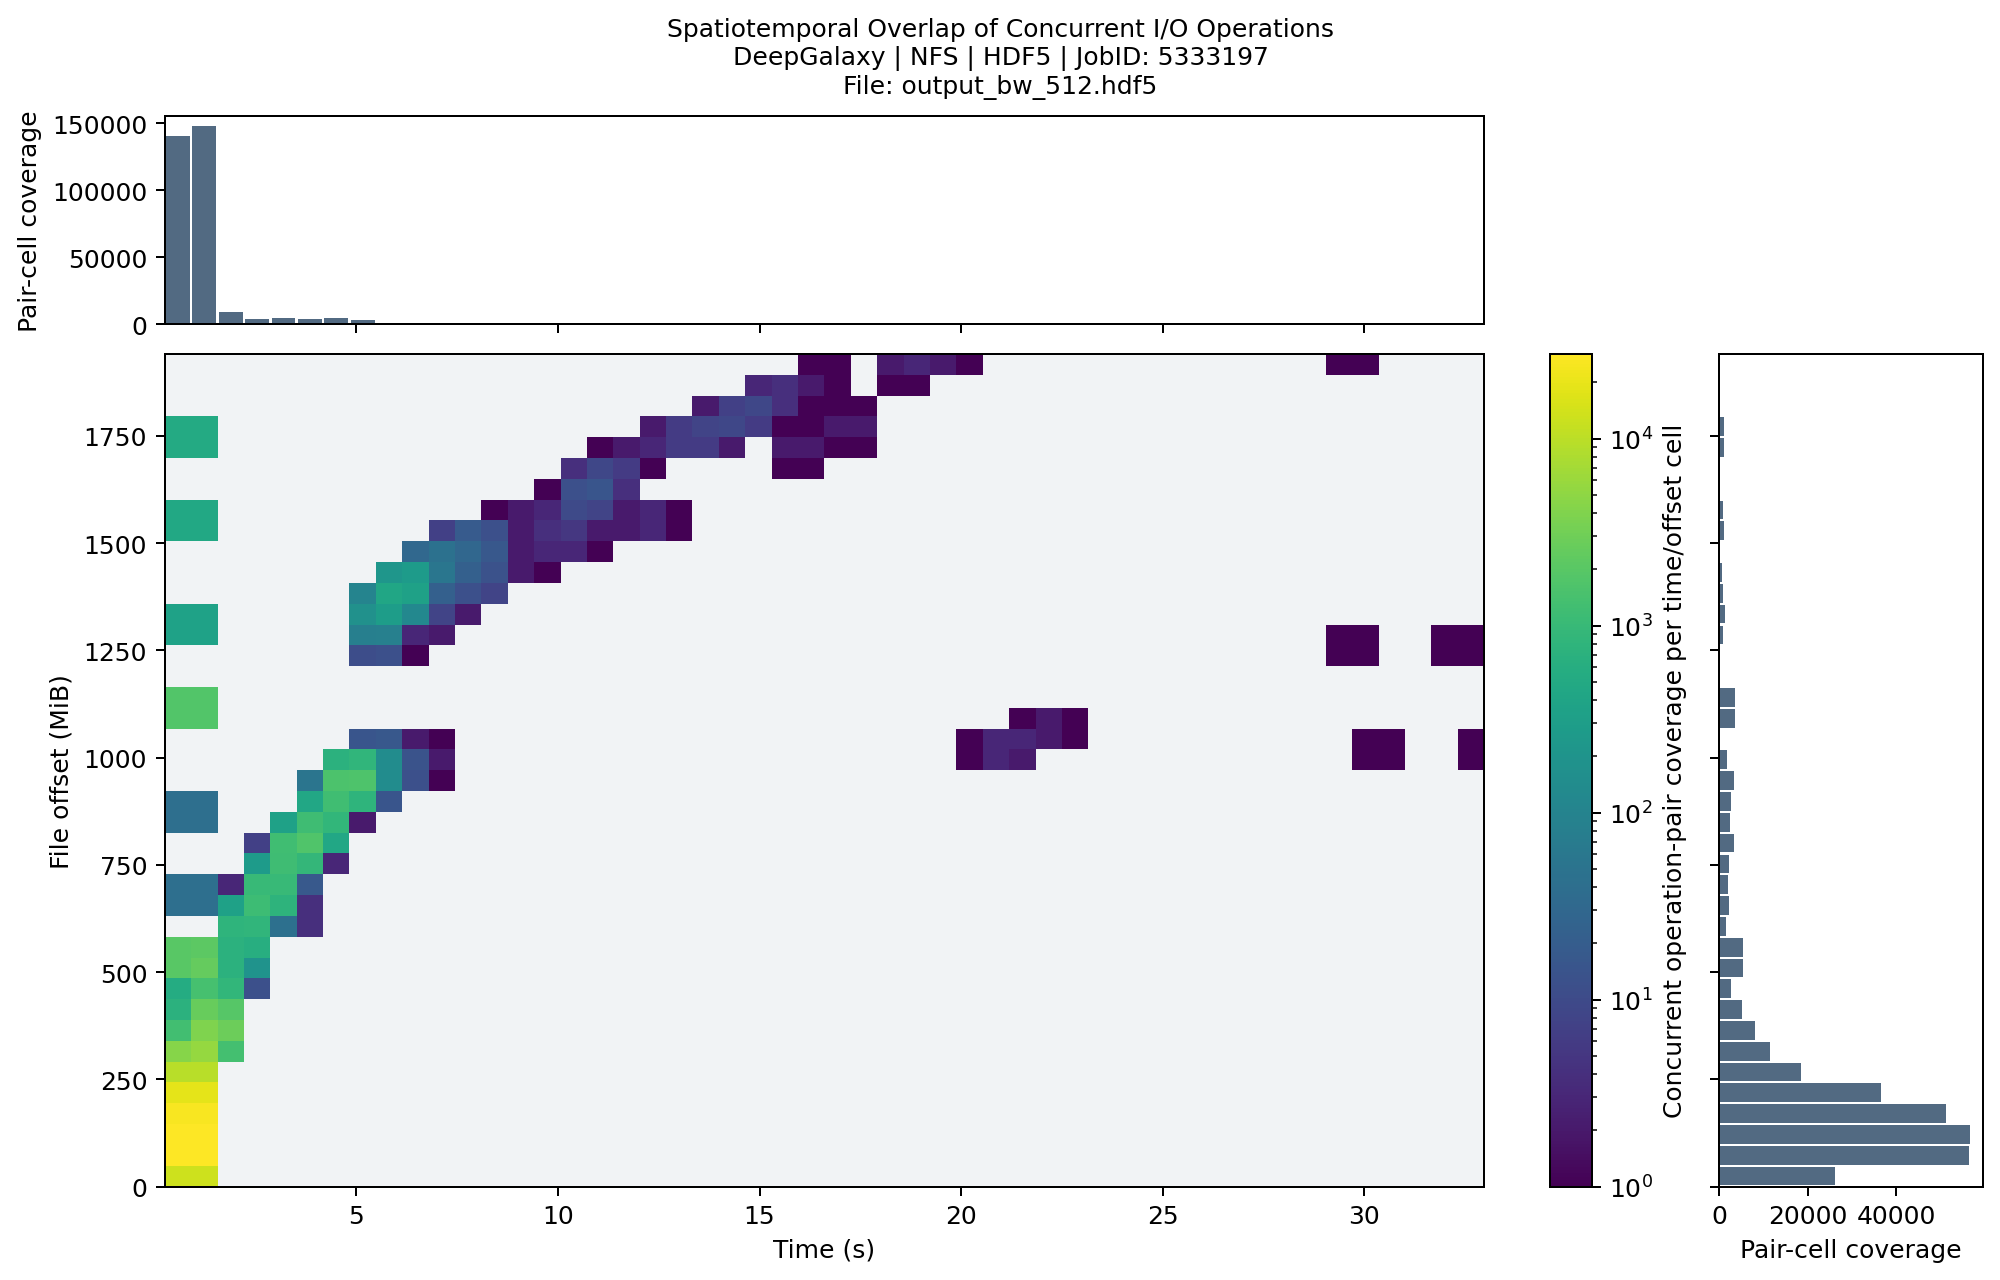

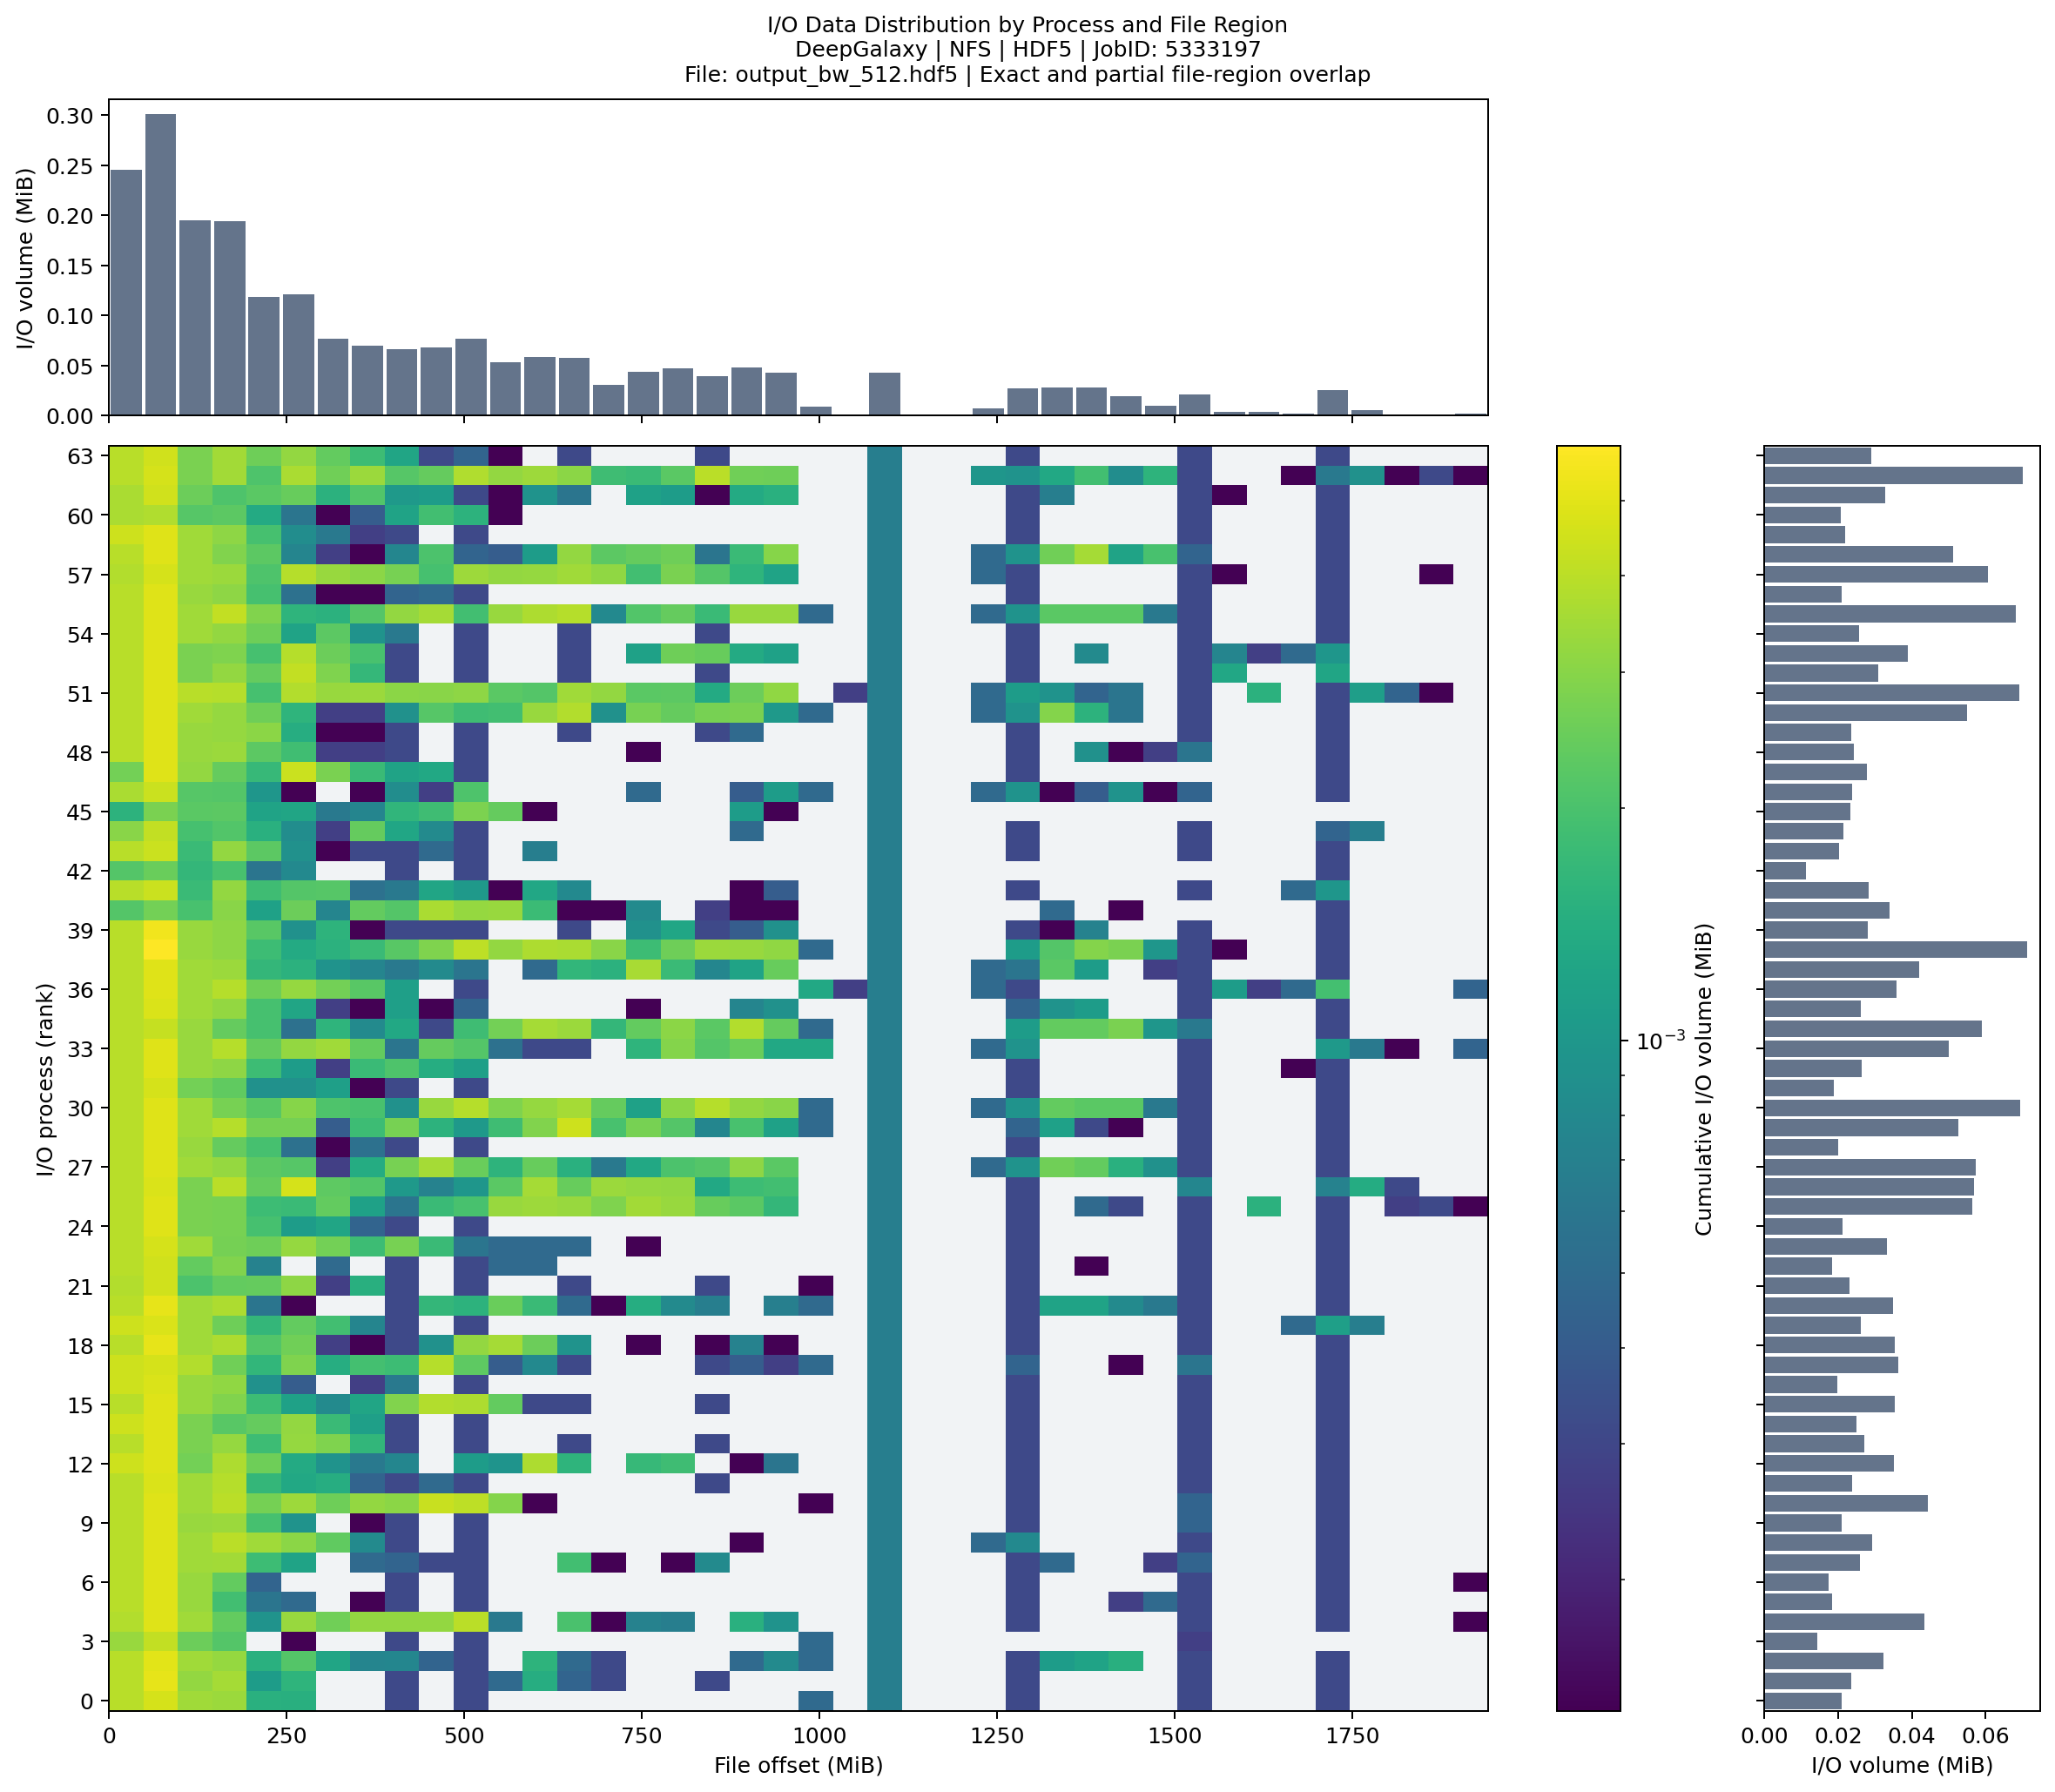

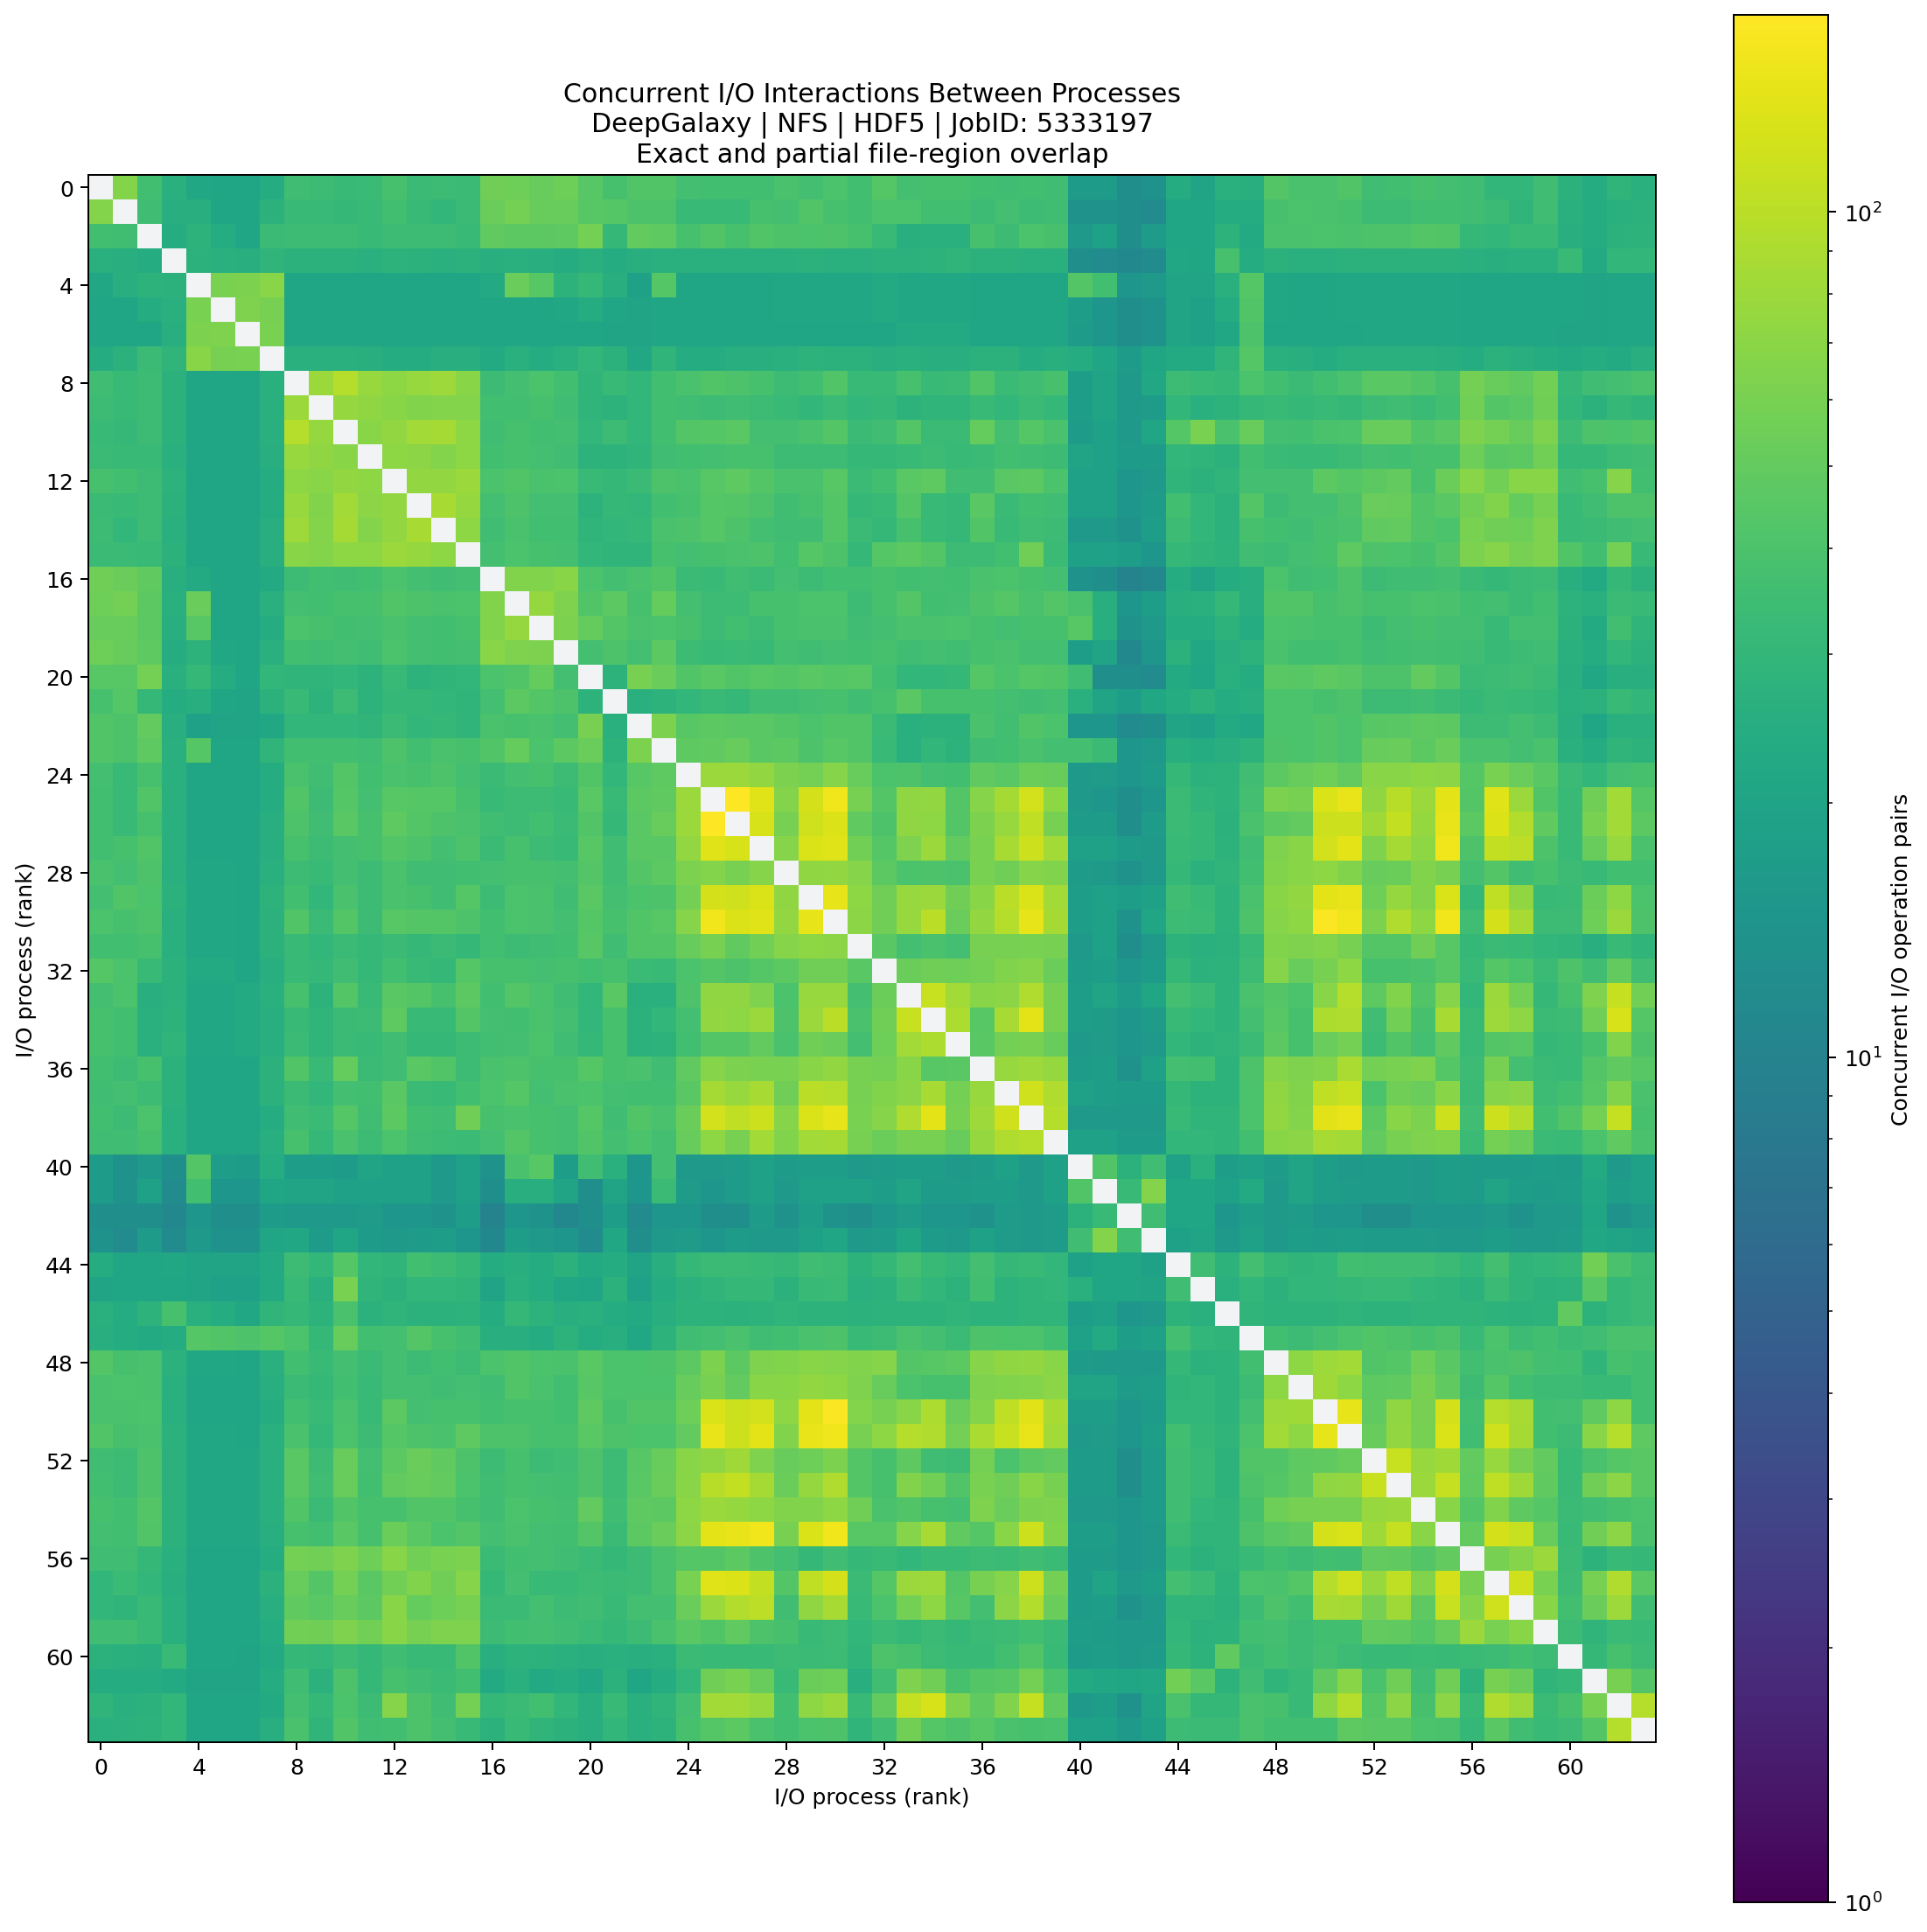

In [3]:
result = run_contention(
    campaign_root=CAMPAIGN_ROOT, application=APPLICATION,
    dataset_group=DATASET_GROUP, scenario=SCENARIO, file_format=FILE_FORMAT,
    job_id=JOBID, operation=OPERATION, case=CASE, process=PROCESS, file=FILE,
    time_bins=TIME_BINS, offset_bins=OFFSET_BINS, max_pairs=MAX_PAIRS,
    resource_mode=RESOURCE_MODE, output_dir=OUTPUT_DIR,
    palette=PALETTE, log_scale=LOG_SCALE,
    process_offset_metric=PROCESS_OFFSET_METRIC,
)
print("Eventos DXT:", result["event_count"])
print("Pares detectados:", result["pair_count"])
print("Casos:", result["diagnostics"].get("cases"))
print("Truncado:", result["diagnostics"].get("truncated"))
print("Fuentes:", *result["source_files"], sep="\n - ")
print("Resultados:", result["output_dir"])
if result["diagnostics"].get("truncated"):
    print("ADVERTENCIA: el detector alcanzó MAX_PAIRS; resultados parciales.")
print("Figuras generadas:", len(result["figures"]))
for figure in result["figures"]:
    print("  -", figure, "| existe:", figure.is_file())
print("Archivos PNG presentes en la carpeta:")
for png in sorted(result["output_dir"].glob("*.png")):
    print("  -", png.name)

if not result["figures"]:
    print("Sin figuras para el filtro seleccionado: comprueba CASE, PROCESS y FILE.")
for fig in result["figures"]:
    display(Image(filename=str(fig)))
